In [5]:
# 📦 تثبيت المكتبات المطلوبة
!pip install -q kaggle

# 📁 إنشاء مجلد للبيانات
!mkdir -p ~/.kaggle

print("🔑 الخطوة 1: تحميل ملف kaggle.json")
print("⚠️ اتبع هذه الخطوات:")
print("1. اذهب إلى: https://www.kaggle.com/settings")
print("2. اضغط 'Create New API Token'")
print("3. سيُحمّل ملف kaggle.json")
print("4. ارفعه في الخلية التالية")

from google.colab import files
uploaded = files.upload()

# نقل الملف
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("\n✅ تم تثبيت Kaggle API بنجاح!")

🔑 الخطوة 1: تحميل ملف kaggle.json
⚠️ اتبع هذه الخطوات:
1. اذهب إلى: https://www.kaggle.com/settings
2. اضغط 'Create New API Token'
3. سيُحمّل ملف kaggle.json
4. ارفعه في الخلية التالية


Saving kaggle.json to kaggle.json

✅ تم تثبيت Kaggle API بنجاح!


In [6]:
#  تحميل بيانات المسابقة
print("🔄 جاري تحميل البيانات من Kaggle...")
!kaggle competitions download -c gan-getting-started
!unzip -q gan-getting-started.zip -d /content/data

# التحقق من البيانات
import os
import glob

MONET_DIR = '/content/data/monet_jpg/'
PHOTO_DIR = '/content/data/photo_jpg/'

monet_files = sorted(glob.glob(MONET_DIR + '*.jpg'))
photo_files = sorted(glob.glob(PHOTO_DIR + '*.jpg'))

print("=" * 60)
print(f"✅ عدد لوحات Monet: {len(monet_files)}")
print(f"✅ عدد الصور الفوتوغرافية: {len(photo_files)}")
print("=" * 60)

🔄 جاري تحميل البيانات من Kaggle...
100% 367M/367M [00:02<00:00, 137MB/s]

✅ عدد لوحات Monet: 300
✅ عدد الصور الفوتوغرافية: 7038


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


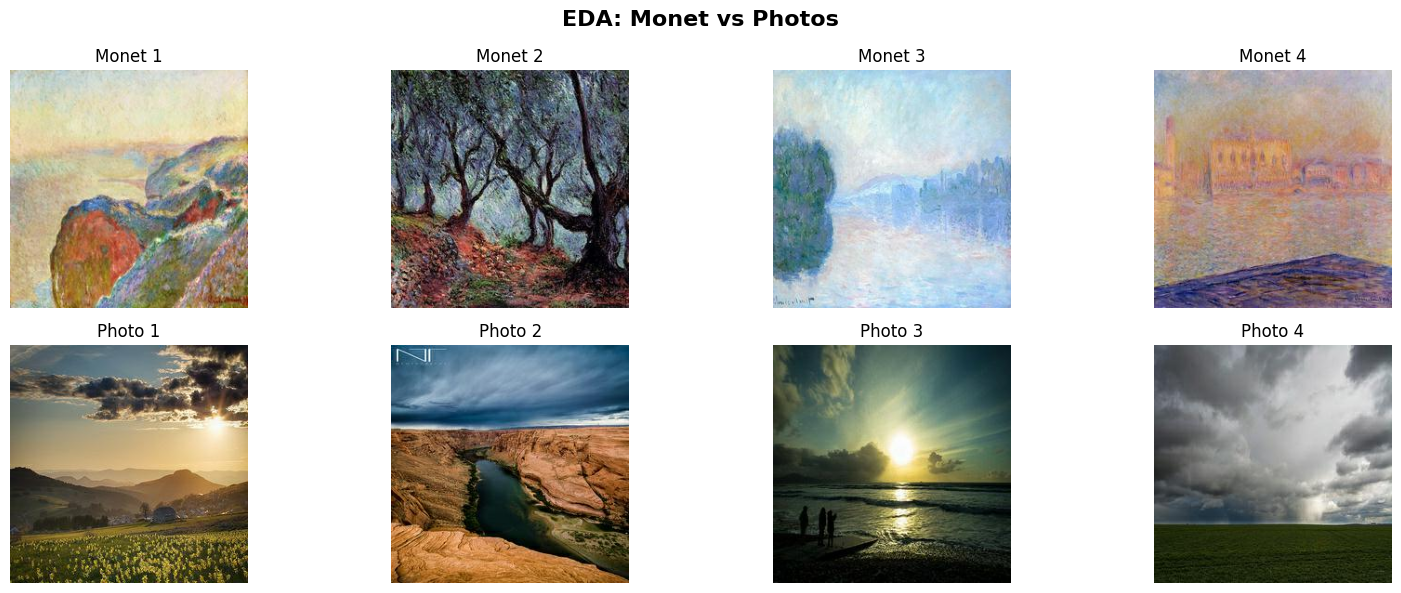

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
import glob
import zipfile

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

#  عرض بعض الصور
def load_image(path, size=(256, 256)):
    img = Image.open(path).resize(size)
    return np.array(img)

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i in range(4):
    axes[0, i].imshow(load_image(monet_files[i]))
    axes[0, i].set_title(f'Monet {i+1}')
    axes[0, i].axis('off')

    axes[1, i].imshow(load_image(photo_files[i]))
    axes[1, i].set_title(f'Photo {i+1}')
    axes[1, i].axis('off')

plt.suptitle('EDA: Monet vs Photos', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
# ️ إعدادات النموذج
IMG_SIZE = 256
BATCH_SIZE = 1
EPOCHS = 10
LAMBDA_CYCLE = 10.0
LAMBDA_IDENTITY = 5.0

# 🏗️ InstanceNormalization مخصص
class InstanceNormalization(layers.Layer):
    def __init__(self, **kwargs):
        super(InstanceNormalization, self).__init__(**kwargs)

    def build(self, input_shape):
        self.scale = self.add_weight(
            name='scale',
            shape=[input_shape[-1]],
            initializer='ones',
            trainable=True
        )
        self.offset = self.add_weight(
            name='offset',
            shape=[input_shape[-1]],
            initializer='zeros',
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        mean, variance = tf.nn.moments(inputs, axes=[1, 2], keepdims=True)
        normalized = (inputs - mean) / tf.sqrt(variance + 1e-5)
        return self.scale * normalized + self.offset

# 🔄 Residual Block
def residual_block(x, filters):
    shortcut = x
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.Add()([x, shortcut])
    return x

#  Generator
def build_generator():
    inputs = layers.Input(shape=[IMG_SIZE, IMG_SIZE, 3])

    # Encoder
    x = layers.Conv2D(64, 7, padding='same', use_bias=False)(inputs)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(128, 3, strides=2, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(256, 3, strides=2, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    # Bottleneck (9 residual blocks)
    for _ in range(9):
        x = residual_block(x, 256)

    # Decoder
    x = layers.Conv2DTranspose(128, 3, strides=2, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2DTranspose(64, 3, strides=2, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    outputs = layers.Conv2D(3, 7, padding='same', activation='tanh')(x)

    return Model(inputs, outputs, name='Generator')

# 👁️ Discriminator
def build_discriminator():
    inputs = layers.Input(shape=[IMG_SIZE, IMG_SIZE, 3])

    x = layers.Conv2D(64, 4, strides=2, padding='same')(inputs)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(128, 4, strides=2, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(256, 4, strides=2, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(512, 4, strides=2, padding='same', use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    outputs = layers.Conv2D(1, 4, padding='same')(x)

    return Model(inputs, outputs, name='Discriminator')

# بناء النماذج
G_photo_to_monet = build_generator()
G_monet_to_photo = build_generator()
D_monet = build_discriminator()
D_photo = build_discriminator()

print("✅ تم بناء النماذج بنجاح!")

✅ تم بناء النماذج بنجاح!


In [9]:
# 📉 Loss Functions
loss_fn = tf.keras.losses.MeanSquaredError()
cycle_loss_fn = tf.keras.losses.MeanAbsoluteError()
identity_loss_fn = tf.keras.losses.MeanAbsoluteError()

# 🎯 Optimizers
optimizer_G = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
optimizer_D = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

@tf.function
def discriminator_loss(real, generated):
    real_loss = loss_fn(tf.ones_like(real), real)
    generated_loss = loss_fn(tf.zeros_like(generated), generated)
    return (real_loss + generated_loss) * 0.5

@tf.function
def generator_loss(generated):
    return loss_fn(tf.ones_like(generated), generated)

#  تحميل البيانات
def load_and_preprocess(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)
    return (img / 127.5) - 1.0

monet_ds = tf.data.Dataset.from_tensor_slices(monet_files)
monet_ds = monet_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
monet_ds = monet_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE).shuffle(100)

photo_ds = tf.data.Dataset.from_tensor_slices(photo_files)
photo_ds = photo_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
photo_ds = photo_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE).shuffle(100)

# 🏋️ Train Step
@tf.function
def train_step(photo, monet):
    with tf.GradientTape(persistent=True) as tape:
        fake_monet = G_photo_to_monet(photo, training=True)
        cycled_photo = G_monet_to_photo(fake_monet, training=True)

        fake_photo = G_monet_to_photo(monet, training=True)
        cycled_monet = G_photo_to_monet(fake_photo, training=True)

        real_monet_pred = D_monet(monet, training=True)
        fake_monet_pred = D_monet(fake_monet, training=True)
        real_photo_pred = D_photo(photo, training=True)
        fake_photo_pred = D_photo(fake_photo, training=True)

        gen_loss_pm = generator_loss(fake_monet_pred)
        gen_loss_mp = generator_loss(fake_photo_pred)

        cycle_loss_p = cycle_loss_fn(photo, cycled_photo) * LAMBDA_CYCLE
        cycle_loss_m = cycle_loss_fn(monet, cycled_monet) * LAMBDA_CYCLE

        total_gen_loss = gen_loss_pm + gen_loss_mp + cycle_loss_p + cycle_loss_m

        disc_loss_monet = discriminator_loss(real_monet_pred, fake_monet_pred)
        disc_loss_photo = discriminator_loss(real_photo_pred, fake_photo_pred)
        total_disc_loss = disc_loss_monet + disc_loss_photo

    gen_vars = (G_photo_to_monet.trainable_variables +
                G_monet_to_photo.trainable_variables)
    gen_grads = tape.gradient(total_gen_loss, gen_vars)
    optimizer_G.apply_gradients(zip(gen_grads, gen_vars))

    disc_vars = D_monet.trainable_variables + D_photo.trainable_variables
    disc_grads = tape.gradient(total_disc_loss, disc_vars)
    optimizer_D.apply_gradients(zip(disc_grads, disc_vars))

    return total_gen_loss, total_disc_loss

print("✅ جاهز للتدريب!")

✅ جاهز للتدريب!


🚀 بدء التدريب...
⏳ Epoch 1/10 - G Loss: 8.6603 - D Loss: 1.2094 - Time: 80.9s
⏳ Epoch 2/10 - G Loss: 6.9064 - D Loss: 0.5596 - Time: 49.9s
⏳ Epoch 3/10 - G Loss: 6.9284 - D Loss: 0.5266 - Time: 48.8s
⏳ Epoch 4/10 - G Loss: 6.5161 - D Loss: 0.4994 - Time: 49.1s
⏳ Epoch 5/10 - G Loss: 6.7739 - D Loss: 0.5163 - Time: 49.0s
⏳ Epoch 6/10 - G Loss: 6.4517 - D Loss: 0.4921 - Time: 48.9s
⏳ Epoch 7/10 - G Loss: 6.4691 - D Loss: 0.4910 - Time: 49.1s
⏳ Epoch 8/10 - G Loss: 6.5273 - D Loss: 0.4543 - Time: 49.1s
⏳ Epoch 9/10 - G Loss: 6.7671 - D Loss: 0.4402 - Time: 49.0s
⏳ Epoch 10/10 - G Loss: 6.2583 - D Loss: 0.4625 - Time: 49.0s
✅ انتهى التدريب بنجاح!


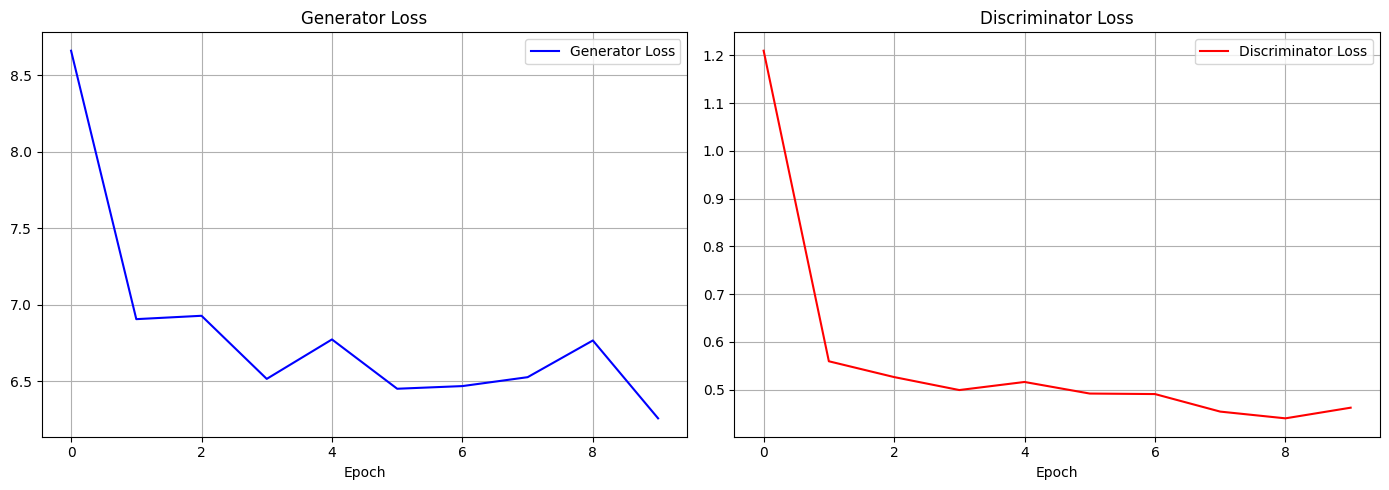

In [10]:
import time

EPOCHS = 10
LAMBDA_CYCLE = 10.0
LAMBDA_IDENTITY = 5.0
IMG_SIZE = 256
BATCH_SIZE = 1

print("=" * 60)
print("🚀 بدء التدريب...")
print("=" * 60)

gen_losses = []
disc_losses = []

for epoch in range(EPOCHS):
    start_time = time.time()
    epoch_gen_loss = 0
    epoch_disc_loss = 0
    n_steps = 0

    dataset = tf.data.Dataset.zip((photo_ds, monet_ds))

    for photo_batch, monet_batch in dataset.take(100):
        gen_loss, disc_loss = train_step(
            tf.expand_dims(photo_batch[0], 0),
            tf.expand_dims(monet_batch[0], 0)
        )

        epoch_gen_loss += gen_loss
        epoch_disc_loss += disc_loss
        n_steps += 1

    avg_gen = epoch_gen_loss / n_steps
    avg_disc = epoch_disc_loss / n_steps
    gen_losses.append(avg_gen.numpy())
    disc_losses.append(avg_disc.numpy())

    elapsed = time.time() - start_time

    print(f"⏳ Epoch {epoch+1}/{EPOCHS} - "
          f"G Loss: {avg_gen:.4f} - D Loss: {avg_disc:.4f} - "
          f"Time: {elapsed:.1f}s")

print("=" * 60)
print("✅ انتهى التدريب بنجاح!")
print("=" * 60)

# 📊 عرض منحنى الـ Loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(gen_losses, 'b-', label='Generator Loss')
axes[0].set_title('Generator Loss')
axes[0].set_xlabel('Epoch')
axes[0].grid(True)
axes[0].legend()

axes[1].plot(disc_losses, 'r-', label='Discriminator Loss')
axes[1].set_title('Discriminator Loss')
axes[1].set_xlabel('Epoch')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

In [11]:
print("🎨 بدء توليد الصور...")
os.makedirs('/content/output', exist_ok=True)

# استخدام كل الصور الفوتوغرافية
test_files = photo_files

for i, test_path in enumerate(test_files):
    img = load_and_preprocess(test_path)
    img_batch = tf.expand_dims(img, 0)

    generated = G_photo_to_monet(img_batch, training=False)

    gen_img = ((generated[0].numpy() + 1) * 127.5).astype(np.uint8)

    Image.fromarray(gen_img).save(f'/content/output/{i}.jpg')

    if (i + 1) % 1000 == 0:
        print(f"  ✅ تم توليد {i+1} صورة...")

print(f"\n🎉 تم توليد {len(test_files)} صورة بنجاح!")

# 📦 إنشاء ملف ZIP
print("\n📦 جاري إنشاء images.zip...")
with zipfile.ZipFile('/content/images.zip', 'w', zipfile.ZIP_DEFLATED) as zipf:
    for i in range(len(test_files)):
        zipf.write(f'/content/output/{i}.jpg', f'{i}.jpg')

print("✅ تم إنشاء images.zip بنجاح!")

# 📥 تحميل الملف تلقائياً
print("\n⏳ جاري تحميل الملف...")
files.download('/content/images.zip')

print("\n🎊 مبروك! تم الانتهاء!")

🎨 بدء توليد الصور...
  ✅ تم توليد 1000 صورة...
  ✅ تم توليد 2000 صورة...
  ✅ تم توليد 3000 صورة...
  ✅ تم توليد 4000 صورة...
  ✅ تم توليد 5000 صورة...
  ✅ تم توليد 6000 صورة...
  ✅ تم توليد 7000 صورة...

🎉 تم توليد 7038 صورة بنجاح!

📦 جاري إنشاء images.zip...
✅ تم إنشاء images.zip بنجاح!

⏳ جاري تحميل الملف...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎊 مبروك! تم الانتهاء!
📌 الخطوة التالية:
1. اذهب إلى: https://www.kaggle.com/competitions/gan-getting-started/submit
2. ارفع ملف images.zip
3. انتظر النتيجة
4. خذ Screenshot للـ Leaderboard
